# Sign Transformer + 臉部特徵 (表情 + 嘴型)

以 `sign_transformer_ctc3.ipynb` 為基礎 (CTC、缺漏遮罩、資料增強都相同)，輸入從 156 維增加到 **292 維**：

| 維度 | 內容 | 來源 |
|---|---|---|
| 0:156 | 跟原本完全一樣 (手 128 + pose 28) | Phase4 `02combined` |
| 156:208 | **52 個表情分數** (blendshapes，0~1)：眉毛、眼睛、張嘴、嘟嘴… | `02keypoint_face.py` |
| 208:288 | **嘴唇 40 點 (x, y)**：以嘴角中點為原點、除以兩眼距離 | 同上 |
| 288:291 | **頭部轉向** (點頭、轉頭、歪頭) | 同上 |
| 291 | 是否偵測到臉 | 同上 |

沒偵測到臉的格，臉部特徵一樣用遮罩設成 0。`USE_BLENDSHAPES`、`USE_LIPS`、`USE_HEAD_POSE` 可以分別關掉，用來比較哪一種臉部資訊最有用。

**執行前要先完成** (每個 part 都要)：
1. Phase4 `02keypoint_face.py` → `01face`
2. Phase4 `03keypoint_combine_face.py` → `02combined_face`
3. Phase5 `03split_npy.py`，`FEATURE_TAG = "_face"`、`MARGIN = 0` → `03segments_face`、`03labels_face`

資料切分與字典沿用 `data/`，所以結果可以直接跟 ctc3 比較；`norm` 另外算一份 292 維的 `norm_masked_face.npz`。

**判斷有沒有效** (跟 `ctc3` 比，ctc3 = 同樣設定但沒有臉部特徵)：
1. 診斷實驗的差距 (ctc3 0.114) 要明顯變大
2. decoder 的**新句 CER** (ctc3 0.994) 要下降、**新句精確率** (ctc3 0.117) 要上升
3. CTC 直接解碼的**新句精確率** (ctc3 0.305)、**新句召回率** (ctc3 0.012) 要上升

之前所有實驗 (切點、CTC、調參數、遮罩、資料增強) 的新句 CER 都卡在 0.99～1.03；如果這次明顯低於這個範圍，就證實「缺少臉部資訊」是主要瓶頸。

In [1]:
import csv
import json
import math
import os
import random
import re
import unicodedata
import warnings
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset
from tqdm import tqdm

warnings.filterwarnings("ignore")
# os.chdir(r"C:\你的專案資料夾\Data Training")

# ================================================================ 實驗設定
SEG_TAG = "_face"          # 分段資料：03segments_face / 03labels_face (含臉部特徵的 292 維)
RUN_TAG = "_face"          # 這次實驗的名稱，checkpoints / predictions 會加上這個後綴

# ================================================================ 路徑設定
LABEL_DIR = Path(r"..\Data Preparation\Phase5-Pause\output\03labels" + SEG_TAG)
SEG_DIR = Path(r"..\Data Preparation\Phase5-Pause\output\03segments" + SEG_TAG)
DATA_DIR = Path(r"data")                              # 沿用原本的資料切分與字典 (句子跟 03segments 一一對應)
CKPT_DIR = Path(r"checkpoints" + RUN_TAG)
PRED_DIR = Path(r"predictions" + RUN_TAG)              # decoder (翻譯) 的預測
PRED_DIR_CTC = Path(r"predictions" + RUN_TAG + "_enc")  # CTC 直接解碼的預測

# ================================================================ 資料集切分 (DATA_DIR 已經有資料時不會重建)
SPLIT = (0.8, 0.1, 0.1)
SEED = 42
SPECIALS = ["<pad>", "<bos>", "<eos>", "<unk>"]
FEAT_DIM = 292            # 156 (手 + pose) + 136 (臉)
FLAG_DIMS = [126, 127, 155, 291]   # 左手、右手、pose、臉是否偵測到

# ================================================================ 臉部特徵開關 (關掉 = 那一組特徵一律設成 0)
USE_BLENDSHAPES = True     # 52 個表情分數
USE_LIPS = True            # 嘴唇 40 點
USE_HEAD_POSE = True       # 頭部轉向
MIN_FREQ = 2

# ================================================================ 資料設定
FRAME_STRIDE = 2
MAX_FRAMES = 300
MAX_TEXT_LEN = 64
SPEED_RANGE = (0.8, 1.2)
NOISE_STD = 0.05           # 只加在有偵測到的座標上，旗標不加

# ================================================================ 新增：缺漏遮罩與資料增強
NORM_FILE = "norm_masked_face.npz"   # 292 維版本，只用有偵測到的格計算 (存在 DATA_DIR，不覆蓋其他 norm)
AUGMENT = True             # False = 只做變速與雜訊 (跟之前一樣)，方便單獨比較遮罩的效果
ROTATE_DEG = 10            # 隨機旋轉 ±幾度 (pose 與手形一起轉，模擬鏡頭微微傾斜)
SCALE_RANGE = (0.9, 1.1)   # pose 隨機縮放 (模擬人離鏡頭遠近)
SHIFT = 0.05               # pose 隨機平移 (畫面寬高的比例)
TIME_MASK_N = 2            # 每句隨機遮掉幾段
TIME_MASK_MAX = 0.1        # 每段最長佔整句的比例

# ================================================================ 模型設定
D_MODEL = 256
N_HEADS = 4
ENC_LAYERS = 4
DEC_LAYERS = 2             # 原本 3
FF_DIM = 1024
DROPOUT = 0.3

# ================================================================ 新增：CTC 與 decoder 遮字
CTC_WEIGHT = 0.5           # 總損失裡 CTC 佔的比例 (同 _ctc；_ctc2 的 0.7 沒有比較好)
WORD_DROPOUT = 0.25        # 訓練時 decoder 輸入有多少比例的字換成 <unk>
NO_REPEAT_NGRAM = 4        # 解碼時禁止同樣的 N 字片段出現第二次 (0 = 不限制)；設 4 而不是 3，避免擋掉「10000」這類數字
MAX_CHAR_RUN = 4           # 同一個字最多連續出現幾次 (擋「天天天天天」；4 才不會擋到「10000」)

# ================================================================ 訓練設定
BATCH_SIZE = 32
EPOCHS = 150
LR = 3e-4
WEIGHT_DECAY = 0.05
WARMUP_EPOCHS = 5
LABEL_SMOOTHING = 0.1
EARLY_STOP_ON = "ce"       # 用哪個 val 損失選模型、判斷提前停止："ce" = 只看翻譯 (同 _ctc)，"total" = 翻譯 + CTC (_ctc2)
PATIENCE = 15              # 連續幾個 epoch 沒進步就停止 (_ctc 是 10；資料增強會讓收斂變慢，所以放寬一點)
VAL_CER_EVERY = 5

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
USE_AMP = DEVICE == "cuda"
PAD, BOS, EOS, UNK = 0, 1, 2, 3
BLANK = PAD                # CTC 的空白符號借用 <pad> (它不會出現在答案裡)
print("device:", DEVICE)

device: cuda


## DATASET
`DATA_DIR` 裡已經有 `train.csv`、`vocab.json`、`norm.npz` 就直接沿用，不重新切分。

In [2]:
if all((DATA_DIR / name).exists() for name in ("train.csv", "val.csv", "test.csv", "vocab.json", "norm.npz")):
    print(f"沿用 {DATA_DIR} 裡現有的資料切分、字典與 norm")
else:
    print(f"{DATA_DIR} 沒有完整資料，重新建立")
    groups = {}
    for txt in sorted(LABEL_DIR.glob("*/*/*.txt")):
        group = txt.parent.relative_to(LABEL_DIR)
        for line in txt.read_text(encoding="utf-8").splitlines():
            name, _, text = line.partition(": ")
            if text.strip():
                groups.setdefault(group.as_posix(), []).append(((group / f"{name}.npy").as_posix(), text.strip()))

    keys = sorted(groups)
    random.Random(SEED).shuffle(keys)
    n_train, n_val = round(len(keys) * SPLIT[0]), round(len(keys) * SPLIT[1])
    splits = {"train": keys[:n_train], "val": keys[n_train:n_train + n_val], "test": keys[n_train + n_val:]}

    DATA_DIR.mkdir(parents=True, exist_ok=True)
    rows = {}
    for split, split_keys in splits.items():
        rows[split] = [row for key in sorted(split_keys) for row in groups[key]]
        with (DATA_DIR / f"{split}.csv").open("w", newline="", encoding="utf-8-sig") as f:
            writer = csv.writer(f)
            writer.writerow(("path", "text"))
            writer.writerows(rows[split])

    freq = Counter(c for _, text in rows["train"] for c in text)
    chars = sorted(c for c, n in freq.items() if n >= MIN_FREQ)
    (DATA_DIR / "vocab.json").write_text(json.dumps(SPECIALS + chars, ensure_ascii=False), encoding="utf-8")

    total, total_sq, count = np.zeros(FEAT_DIM), np.zeros(FEAT_DIM), 0
    for path, _ in tqdm(rows["train"], desc="norm"):
        arr = np.load(SEG_DIR / path).astype(np.float64)
        total += arr.sum(0)
        total_sq += (arr ** 2).sum(0)
        count += len(arr)
    mean = total / count
    std = np.sqrt(np.maximum(total_sq / count - mean ** 2, 0)) + 1e-6
    mean[FLAG_DIMS], std[FLAG_DIMS] = 0.0, 1.0
    np.savez(DATA_DIR / "norm.npz", mean=mean.astype(np.float32), std=std.astype(np.float32))

for split in ("train", "val", "test"):
    with (DATA_DIR / f"{split}.csv").open(encoding="utf-8-sig", newline="") as f:
        print(f"{split}: {sum(1 for _ in csv.DictReader(f))} 句")
print("字元數:", len(json.loads((DATA_DIR / "vocab.json").read_text(encoding="utf-8"))) - len(SPECIALS))

# ---------------------------------------------------------------- 特徵位置與缺漏遮罩
LEFT, RIGHT, POSE = slice(0, 63), slice(63, 126), slice(128, 155)
LEFT_FLAG, RIGHT_FLAG, POSE_FLAG = 126, 127, 155
BLENDSHAPES, LIPS, HEAD_POSE, FACE_FLAG = slice(156, 208), slice(208, 288), slice(288, 291), 291


def valid_mask(arr):
    """(T, FEAT_DIM) 的 bool：每一維是不是真的有偵測到。旗標本身永遠算有效。"""
    m = np.ones(arr.shape, dtype=bool)
    m[:, LEFT] = arr[:, [LEFT_FLAG]] > 0.5
    m[:, RIGHT] = arr[:, [RIGHT_FLAG]] > 0.5
    point_ok = (arr[:, POSE].reshape(-1, 9, 3)[:, :, 2] > 0) & (arr[:, [POSE_FLAG]] > 0.5)   # 信心值 0 = 這個點沒偵測到
    m[:, POSE] = np.repeat(point_ok, 3, axis=1)
    m[:, 156:FACE_FLAG] = arr[:, [FACE_FLAG]] > 0.5            # 沒偵測到臉 → 臉部特徵全部無效
    for part, use in ((BLENDSHAPES, USE_BLENDSHAPES), (LIPS, USE_LIPS), (HEAD_POSE, USE_HEAD_POSE)):
        if not use:
            m[:, part] = False                                   # 關掉的特徵組一律設成 0
    return m


if (DATA_DIR / NORM_FILE).exists():
    print(f"沿用 {DATA_DIR / NORM_FILE}")
else:
    with (DATA_DIR / "train.csv").open(encoding="utf-8-sig", newline="") as f:
        train_paths = [row["path"] for row in csv.DictReader(f)]
    total, total_sq, count = np.zeros(FEAT_DIM), np.zeros(FEAT_DIM), np.zeros(FEAT_DIM)
    for path in tqdm(train_paths, desc="masked norm"):
        arr = np.load(SEG_DIR / path).astype(np.float64)
        m = valid_mask(arr)
        arr = np.where(m, arr, 0.0)
        total += arr.sum(0)
        total_sq += (arr ** 2).sum(0)
        count += m.sum(0)
    mean = total / np.maximum(count, 1)
    std = np.sqrt(np.maximum(total_sq / np.maximum(count, 1) - mean ** 2, 0)) + 1e-6
    mean[FLAG_DIMS], std[FLAG_DIMS] = 0.0, 1.0
    np.savez(DATA_DIR / NORM_FILE, mean=mean.astype(np.float32), std=std.astype(np.float32),
             valid_ratio=(count / count.max()).astype(np.float32),
             flag_rate=(total / np.maximum(count, 1))[FLAG_DIMS].astype(np.float32))   # 左手、右手、pose、臉的偵測率
    print(f"已存成 {DATA_DIR / NORM_FILE}")

ratio = np.load(DATA_DIR / NORM_FILE)["valid_ratio"]
print(f"訓練集偵測率：左手 {ratio[0]:.1%}、右手 {ratio[63]:.1%}、左腕 {ratio[128 + 3 * 5]:.1%}、右腕 {ratio[128 + 3 * 6]:.1%}、"
      f"臉 {np.load(DATA_DIR / NORM_FILE)['flag_rate'][-1]:.1%}")
print(f"臉部特徵：表情分數 {'開' if USE_BLENDSHAPES else '關'}、嘴唇 {'開' if USE_LIPS else '關'}、頭部轉向 {'開' if USE_HEAD_POSE else '關'}")
with (DATA_DIR / "train.csv").open(encoding="utf-8-sig", newline="") as f:
    first = next(csv.DictReader(f))["path"]
dim = np.load(SEG_DIR / first, mmap_mode="r").shape[1]
assert dim == FEAT_DIM, f"{SEG_DIR / first} 是 {dim} 維，應該是 {FEAT_DIM} 維：請確認 Phase4/5 已經用臉部版本重新產生"

沿用 data 裡現有的資料切分、字典與 norm
train: 17901 句
val: 2234 句
test: 2265 句
字元數: 2662


masked norm: 100%|██████████| 17901/17901 [01:59<00:00, 149.98it/s]

已存成 data\norm_masked_face.npz
訓練集偵測率：左手 70.1%、右手 93.6%、左腕 99.2%、右腕 99.7%、臉 99.5%
臉部特徵：表情分數 開、嘴唇 開、頭部轉向 開


In [3]:
def load_vocab():
    return json.loads((DATA_DIR / "vocab.json").read_text(encoding="utf-8"))


def augment_geometry(x):
    """隨機旋轉 (pose 與手形一起轉)、pose 縮放與平移。輸入是還沒標準化的原始座標。"""
    x = x.copy()
    T = len(x)
    angle = np.deg2rad(np.random.uniform(-ROTATE_DEG, ROTATE_DEG))
    c, s = np.cos(angle), np.sin(angle)
    rot = np.array([[c, -s], [s, c]], dtype=np.float32)

    pose = x[:, POSE].reshape(T, 9, 3)
    ok = pose[:, :, 2:] > 0
    xy = (pose[:, :, :2] - 0.5) @ rot.T * np.random.uniform(*SCALE_RANGE) + 0.5 \
        + np.random.uniform(-SHIFT, SHIFT, 2).astype(np.float32)
    pose[:, :, :2] = np.where(ok, xy, 0.0)
    x[:, POSE] = pose.reshape(T, -1)

    hands = x[:, :126].reshape(T, 2, 21, 3)          # 手形已經以手腕為原點，直接轉 (沒偵測到的是 0，轉完還是 0)
    hands[..., :2] = hands[..., :2] @ rot.T
    x[:, :126] = hands.reshape(T, -1)
    return x


def time_mask(x):
    """隨機把幾段連續的格整段設成 0 (含旗標)，模擬遮擋或漏偵測。"""
    T = len(x)
    for _ in range(TIME_MASK_N):
        width = np.random.randint(0, max(1, int(T * TIME_MASK_MAX)) + 1)
        if width:
            start = np.random.randint(0, T - width + 1)
            x[start:start + width] = 0.0
    return x


class SignDataset(Dataset):
    def __init__(self, split, vocab, train=False):
        with (DATA_DIR / f"{split}.csv").open(encoding="utf-8-sig", newline="") as f:
            self.rows = [(row["path"], row["text"]) for row in csv.DictReader(f)]
        self.stoi = {c: i for i, c in enumerate(vocab)}
        norm = np.load(DATA_DIR / NORM_FILE)
        self.mean, self.std = norm["mean"], norm["std"]
        self.train = train
        # 快取「原始值」(只做取樣)，資料增強要在標準化之前做
        self.cache = [
            np.ascontiguousarray(np.load(SEG_DIR / path).astype(np.float32)[::FRAME_STRIDE])
            for path, _ in tqdm(self.rows, desc=f"load {split}")
        ]

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, i):
        text = self.rows[i][1]
        raw = self.cache[i]
        if self.train:
            n = max(1, round(len(raw) * random.uniform(*SPEED_RANGE)))
            raw = raw[np.linspace(0, len(raw) - 1, n).round().astype(int)]
            if AUGMENT:
                raw = augment_geometry(raw)

        mask = valid_mask(raw)
        x = np.where(mask, (raw - self.mean) / self.std, 0.0).astype(np.float32)   # 沒偵測到的一律 0

        if self.train:
            noise = np.random.normal(0, NOISE_STD, x.shape).astype(np.float32)
            noise[:, FLAG_DIMS] = 0.0
            x = x + noise * mask                       # 雜訊只加在有偵測到的座標
            if AUGMENT:
                x = time_mask(x)
        x = x[:MAX_FRAMES]
        ids = [BOS] + [self.stoi.get(c, UNK) for c in text[:MAX_TEXT_LEN - 2]] + [EOS]
        return torch.from_numpy(np.ascontiguousarray(x)), torch.tensor(ids)


def collate(batch):
    xs, ys = zip(*batch)
    src = nn.utils.rnn.pad_sequence(xs, batch_first=True)
    lengths = torch.tensor([len(x) for x in xs])
    src_mask = torch.arange(src.size(1))[None, :] >= lengths[:, None]     # True = padding
    tgt = nn.utils.rnn.pad_sequence(ys, batch_first=True, padding_value=PAD)
    return src, src_mask, tgt

In [4]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=2000):
        super().__init__()
        pos = torch.arange(max_len).unsqueeze(1)
        div = torch.exp(torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model))
        pe = torch.zeros(max_len, d_model)
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe)

    def forward(self, x):
        return x + self.pe[:x.size(1)]


class SignTransformerCTC(nn.Module):
    def __init__(self, vocab_size, feat_dim=FEAT_DIM):
        super().__init__()
        self.src_proj = nn.Sequential(
            nn.Linear(feat_dim, D_MODEL), nn.LayerNorm(D_MODEL), nn.GELU(),
            nn.Dropout(DROPOUT), nn.Linear(D_MODEL, D_MODEL),
        )
        self.tgt_emb = nn.Embedding(vocab_size, D_MODEL, padding_idx=PAD)
        self.pos = PositionalEncoding(D_MODEL)
        self.transformer = nn.Transformer(
            D_MODEL, N_HEADS, ENC_LAYERS, DEC_LAYERS, FF_DIM, DROPOUT,
            batch_first=True, norm_first=True,
        )
        self.out = nn.Linear(D_MODEL, vocab_size)
        # 新增：encoder 每個 frame 直接預測字 (含 blank)
        self.ctc_norm = nn.LayerNorm(D_MODEL)
        self.ctc_out = nn.Linear(D_MODEL, vocab_size)

    def encode(self, src, src_mask):
        return self.transformer.encoder(self.pos(self.src_proj(src)), src_key_padding_mask=src_mask)

    def ctc_logits(self, memory):
        return self.ctc_out(self.ctc_norm(memory))

    def decode(self, tgt, memory, src_mask):
        L = tgt.size(1)
        causal = torch.triu(torch.ones(L, L, dtype=torch.bool, device=tgt.device), 1)
        h = self.transformer.decoder(
            self.pos(self.tgt_emb(tgt) * math.sqrt(D_MODEL)), memory,
            tgt_mask=causal, tgt_key_padding_mask=tgt == PAD, memory_key_padding_mask=src_mask,
        )
        return self.out(h)

    def forward(self, src, src_mask, tgt_in):
        """回傳 (decoder logits, CTC logits)。訓練時 decoder 輸入會隨機遮字。"""
        memory = self.encode(src, src_mask)
        if self.training and WORD_DROPOUT > 0:
            drop = (torch.rand(tgt_in.shape, device=tgt_in.device) < WORD_DROPOUT) & (tgt_in > UNK)
            tgt_in = tgt_in.masked_fill(drop, UNK)          # <bos>、<pad> 不遮
        return self.decode(tgt_in, memory, src_mask), self.ctc_logits(memory)

In [5]:
def compute_loss(model, src, src_mask, tgt, ce_criterion, ctc_criterion):
    """回傳 (總損失, 翻譯損失, CTC 損失)。"""
    logits, ctc_logits = model(src, src_mask, tgt[:, :-1])
    ce = ce_criterion(logits.reshape(-1, logits.size(-1)), tgt[:, 1:].reshape(-1))

    # CTC 的答案 = 去掉 <bos> / <eos> / <pad> 的字
    gold = tgt[:, 1:]
    keep = (gold != PAD) & (gold != EOS)
    log_probs = ctc_logits.float().log_softmax(-1).transpose(0, 1)       # (T, N, C)
    input_lengths = (~src_mask).sum(1)
    ctc = ctc_criterion(log_probs, gold[keep], input_lengths, keep.sum(1))
    return (1 - CTC_WEIGHT) * ce + CTC_WEIGHT * ctc, ce, ctc


def run_epoch(model, loader, ce_criterion, ctc_criterion, optimizer=None, scheduler=None, scaler=None,
              zero_input=False):
    """回傳 (平均翻譯損失, 平均 CTC 損失)，翻譯損失以字數加權。"""
    train = optimizer is not None
    model.train(train)
    ce_total = ctc_total = 0.0
    count = n_batch = 0
    for src, src_mask, tgt in loader:
        if zero_input:
            src = torch.zeros_like(src)
        src, src_mask, tgt = src.to(DEVICE), src_mask.to(DEVICE), tgt.to(DEVICE)
        with torch.set_grad_enabled(train), torch.autocast(DEVICE, enabled=USE_AMP):
            loss, ce, ctc = compute_loss(model, src, src_mask, tgt, ce_criterion, ctc_criterion)
        if train:
            optimizer.zero_grad()
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            if scheduler is not None:
                scheduler.step()
        n = (tgt[:, 1:] != PAD).sum().item()
        ce_total += ce.item() * n
        count += n
        ctc_total += ctc.item()
        n_batch += 1
    return ce_total / count, ctc_total / max(1, n_batch)

In [6]:
def banned_tokens(seq, n, max_run=0):
    """seq 再接哪些字會讓某個 n 字片段第二次出現，或讓同一個字連續超過 max_run 次。"""
    banned = []
    if n > 0 and len(seq) >= n - 1:
        prefix = tuple(seq[len(seq) - (n - 1):]) if n > 1 else ()
        banned = [seq[i + n - 1] for i in range(len(seq) - n + 1) if tuple(seq[i:i + n - 1]) == prefix]
    if max_run > 0 and len(seq) >= max_run and len(set(seq[-max_run:])) == 1:
        banned.append(seq[-1])
    return banned


@torch.no_grad()
def greedy_decode(model, src, src_mask):
    memory = model.encode(src, src_mask)
    ys = torch.full((src.size(0), 1), BOS, dtype=torch.long, device=src.device)
    done = torch.zeros(src.size(0), dtype=torch.bool, device=src.device)
    for _ in range(MAX_TEXT_LEN - 1):
        logits = model.decode(ys, memory, src_mask)[:, -1].float()
        if NO_REPEAT_NGRAM > 0 or MAX_CHAR_RUN > 0:
            for b, seq in enumerate(ys[:, 1:].tolist()):
                banned = banned_tokens(seq, NO_REPEAT_NGRAM, MAX_CHAR_RUN)
                if banned:
                    logits[b, banned] = float("-inf")
        next_tok = logits.argmax(-1)
        next_tok[done] = PAD
        ys = torch.cat([ys, next_tok[:, None]], dim=1)
        done |= next_tok == EOS
        if done.all():
            break
    return ys[:, 1:].tolist()


@torch.no_grad()
def ctc_greedy_decode(model, src, src_mask):
    """CTC 直接解碼：每個 frame 取最大值 → 合併連續重複 → 去掉 blank。"""
    best = model.ctc_logits(model.encode(src, src_mask)).argmax(-1).masked_fill(src_mask, BLANK)
    out = []
    for row in best.tolist():
        ids, prev = [], BLANK
        for t in row:
            if t != prev and t not in (BLANK, BOS, EOS):
                ids.append(t)
            prev = t
        out.append(ids + [EOS])
    return out


def ids_to_text(ids, vocab):
    chars = []
    for i in ids:
        if i in (EOS, PAD):
            break
        chars.append("□" if i == UNK else vocab[i])
    return "".join(chars)


def edit_distance(a, b):
    row = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        prev, row[0] = row[0], i
        for j, cb in enumerate(b, 1):
            prev, row[j] = row[j], min(row[j] + 1, row[j - 1] + 1, prev + (ca != cb))
    return row[-1]


def char_error_rate(preds, refs):
    """字元錯誤率：編輯距離總和 ÷ 正確答案總字數，越低越好。"""
    return sum(edit_distance(p, r) for p, r in zip(preds, refs)) / max(1, sum(len(r) for r in refs))


def predict_loader(model, loader, vocab, decoder=greedy_decode):
    model.eval()
    preds = []
    for src, src_mask, _ in loader:
        with torch.autocast(DEVICE, enabled=USE_AMP):
            out = decoder(model, src.to(DEVICE), src_mask.to(DEVICE))
        preds += [ids_to_text(ids, vocab) for ids in out]
    return preds

## 診斷實驗：有手勢 vs 沒有手勢
跟原本 notebook 一樣的做法 (各訓練 15 個 epoch，比較 val 翻譯損失)，但用的是新模型。

之前的結果：原本切法 0.074、`_ctc` 0.112、`_ctc3` 0.114。**差距要比 ctc3 的 0.114 明顯大，才代表臉部特徵提供了新的資訊。** (這裡的「沒有手勢」是把手、pose、臉全部設成 0)

這格大約要 10 分鐘；如果時間不夠可以跳過，直接跑 Train。

In [7]:
def quick_train(train_set, val_set, epochs, zero_input=False):
    tl = DataLoader(train_set, BATCH_SIZE, shuffle=True, collate_fn=collate)
    vl = DataLoader(val_set, BATCH_SIZE, collate_fn=collate)
    m = SignTransformerCTC(len(vocab)).to(DEVICE)
    opt = torch.optim.AdamW(m.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    sc = torch.amp.GradScaler(enabled=USE_AMP)
    ce_crit = nn.CrossEntropyLoss(ignore_index=PAD)
    ctc_crit = nn.CTCLoss(blank=BLANK, zero_infinity=True)
    best = float("inf")
    for _ in tqdm(range(epochs), desc="zero input" if zero_input else "real input"):
        run_epoch(m, tl, ce_crit, ctc_crit, opt, scaler=sc, zero_input=zero_input)
        with torch.no_grad():
            best = min(best, run_epoch(m, vl, ce_crit, ctc_crit, zero_input=zero_input)[0])
    return best


random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

vocab = load_vocab()
train_set = SignDataset("train", vocab, train=True)
val_set = SignDataset("val", vocab)

real_loss = quick_train(train_set, val_set, 15)
zero_loss = quick_train(train_set, val_set, 15, zero_input=True)
print(f"有手勢 val loss = {real_loss:.3f}，沒有手勢 val loss = {zero_loss:.3f}，差距 = {zero_loss - real_loss:.3f}")
print("(之前：原本切法 0.074、_ctc 0.112、_ctc3 0.114)")

zero input: 100%|██████████| 15/15 [05:43<00:00, 22.91s/it]

有手勢 val loss = 4.210，沒有手勢 val loss = 4.344，差距 = 0.134
(之前：原本切法 0.074、_ctc 0.112、_ctc3 0.114)


## Train

In [8]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

vocab = load_vocab()
train_set = SignDataset("train", vocab, train=True)
val_set = SignDataset("val", vocab)
train_loader = DataLoader(train_set, BATCH_SIZE, shuffle=True, collate_fn=collate)
val_loader = DataLoader(val_set, BATCH_SIZE, collate_fn=collate)
val_refs = [text for _, text in val_set.rows]

model = SignTransformerCTC(len(vocab)).to(DEVICE)
ce_criterion = nn.CrossEntropyLoss(ignore_index=PAD, label_smoothing=LABEL_SMOOTHING)
ctc_criterion = nn.CTCLoss(blank=BLANK, zero_infinity=True)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
total_steps, warmup = EPOCHS * len(train_loader), WARMUP_EPOCHS * len(train_loader)
scheduler = torch.optim.lr_scheduler.LambdaLR(
    optimizer,
    lambda step: step / warmup if step < warmup
    else 0.5 * (1 + math.cos(math.pi * (step - warmup) / max(1, total_steps - warmup))),
)
scaler = torch.amp.GradScaler(enabled=USE_AMP)

CKPT_DIR.mkdir(parents=True, exist_ok=True)
history = []
best_loss, best_epoch, stale = float("inf"), 0, 0
bar = tqdm(range(1, EPOCHS + 1), desc="epoch")
for epoch in bar:
    train_ce, train_ctc = run_epoch(model, train_loader, ce_criterion, ctc_criterion, optimizer, scheduler, scaler)
    with torch.no_grad():
        val_ce, val_ctc = run_epoch(model, val_loader, ce_criterion, ctc_criterion)
    if epoch % VAL_CER_EVERY == 0:
        val_cer = char_error_rate(predict_loader(model, val_loader, vocab), val_refs)
        val_cer_ctc = char_error_rate(predict_loader(model, val_loader, vocab, ctc_greedy_decode), val_refs)
    else:
        val_cer = val_cer_ctc = float("nan")
    history.append((train_ce, val_ce, train_ctc, val_ctc, val_cer, val_cer_ctc))

    # 用 val 總損失 (或只用翻譯損失) 選模型、判斷提前停止
    val_total = (1 - CTC_WEIGHT) * val_ce + CTC_WEIGHT * val_ctc
    score = val_total if EARLY_STOP_ON == "total" else val_ce
    torch.save(model.state_dict(), CKPT_DIR / "last.pt")
    if score < best_loss:
        best_loss, best_epoch, stale = score, epoch, 0
        torch.save(model.state_dict(), CKPT_DIR / "best.pt")
    else:
        stale += 1
    bar.set_postfix(train=f"{train_ce:.3f}", val=f"{val_ce:.3f}", ctc=f"{val_ctc:.2f}",
                    cer=f"{val_cer:.3f}", best=f"{best_loss:.3f}")
    if stale >= PATIENCE:
        break

h = np.array(history)
print(f"最佳 epoch {best_epoch}：val 翻譯損失 {h[best_epoch - 1, 1]:.3f}、val CTC 損失 {h[best_epoch - 1, 3]:.3f}")
print("(ctc3：最佳 val 翻譯損失 4.776，第 21 個 epoch；val CTC 損失 6.331)")

epoch:  25%|██▍       | 37/150 [15:51<48:25, 25.72s/it, best=4.778, cer=nan, ctc=6.97, train=4.046, val=4.925]    

最佳 epoch 23：val 翻譯損失 4.778、val CTC 損失 6.406
(ctc3：最佳 val 翻譯損失 4.776，第 21 個 epoch；val CTC 損失 6.331)


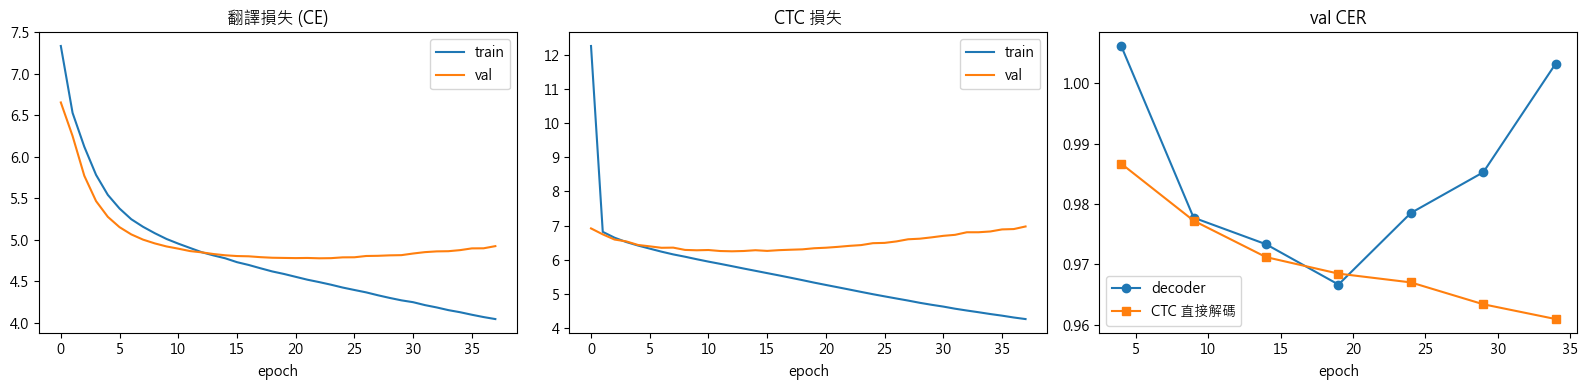

In [13]:
# 訓練曲線
import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["Microsoft JhengHei", "Noto Sans CJK TC", "DejaVu Sans"]   # 中文標題
plt.rcParams["axes.unicode_minus"] = False

h = np.array(history)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(h[:, 0], label="train")
axes[0].plot(h[:, 1], label="val")
axes[0].set_title("翻譯損失 (CE)")
axes[1].plot(h[:, 2], label="train")
axes[1].plot(h[:, 3], label="val")
axes[1].set_title("CTC 損失")
ok = ~np.isnan(h[:, 4])
axes[2].plot(np.where(ok)[0], h[ok, 4], "o-", label="decoder")
axes[2].plot(np.where(ok)[0], h[ok, 5], "s-", label="CTC 直接解碼")
axes[2].set_title("val CER")
for ax in axes:
    ax.set_xlabel("epoch")
    ax.legend()
plt.tight_layout()
plt.show()

## Predictions
同時輸出 decoder (翻譯) 與 CTC 直接解碼兩份預測。

In [10]:
PRED_SPLIT = "test"

vocab = load_vocab()
dataset = SignDataset(PRED_SPLIT, vocab)
loader = DataLoader(dataset, BATCH_SIZE, collate_fn=collate)

model = SignTransformerCTC(len(vocab)).to(DEVICE)
model.load_state_dict(torch.load(CKPT_DIR / "best.pt", map_location=DEVICE))
refs = [text for _, text in dataset.rows]

for pred_dir, decoder, label in ((PRED_DIR, greedy_decode, "decoder"), (PRED_DIR_CTC, ctc_greedy_decode, "CTC")):
    preds = predict_loader(model, loader, vocab, decoder)
    pred_dir.mkdir(parents=True, exist_ok=True)
    with (pred_dir / f"{PRED_SPLIT}_predictions.csv").open("w", newline="", encoding="utf-8-sig") as f:
        writer = csv.writer(f)
        writer.writerow(("path", "target", "prediction"))
        writer.writerows((path, ref, pred) for (path, _), ref, pred in zip(dataset.rows, refs, preds))
    print(f"{label}：{PRED_SPLIT} CER = {char_error_rate(preds, refs):.3f}")
    for (path, _), ref, pred in list(zip(dataset.rows, refs, preds))[:5]:
        print(f"  {path}\n    答案：{ref}\n    預測：{pred}")
    print()

load test: 100%|██████████| 2265/2265 [00:16<00:00, 140.84it/s]


decoder：test CER = 0.958
  2/10/000641_001738_s00.npy
    答案：台鐵445次台東往樹林的普悠瑪號
    預測：美國總統川普昨天宣布
  2/10/000641_001738_s01.npy
    答案：昨天晚間9點多行經和平站附近時
    預測：中國時報是 花蓮光復鄉
  2/10/000641_001738_s02.npy
    答案：撞到一顆巨大落石
    預測：造成一名騎樓倒塌
  2/10/000641_001738_s03.npy
    答案：導致1到3節車廂出軌
    預測：不過民眾黨團體認為
  2/10/000641_001738_s04.npy
    答案：所幸沒有翻覆 旅客都平安
    預測：不過去年的時候

CTC：test CER = 0.962
  2/10/000641_001738_s00.npy
    答案：台鐵445次台東往樹林的普悠瑪號
    預測：昨
  2/10/000641_001738_s01.npy
    答案：昨天晚間9點多行經和平站附近時
    預測：中國
  2/10/000641_001738_s02.npy
    答案：撞到一顆巨大落石
    預測：
  2/10/000641_001738_s03.npy
    答案：導致1到3節車廂出軌
    預測：
  2/10/000641_001738_s04.npy
    答案：所幸沒有翻覆 旅客都平安
    預測：



## 評估
跟原本 notebook 的評估方式相同：基準線、套句 vs 新句、去除重複迴圈、字元精確率 / 召回率。

In [11]:
# 迴圈 = 同一個字連續 5 次以上，或同一段 2~4 字連續 3 次以上 (「5000」「999」「111年」不算)
LOOP_RE = re.compile(r"(.)\1{4,}|(.{2,4}?)\2{2,}")


def pad(text, width, left=True):
    """依顯示寬度補空白 (中文字佔 2 格)，讓表格對齊。"""
    w = sum(2 if unicodedata.east_asian_width(ch) in "WF" else 1 for ch in str(text))
    space = " " * max(0, width - w)
    return f"{text}{space}" if left else f"{space}{text}"


def table_row(label, values, label_width=24, width=12):
    cells = [pad("" if v is None else (f"{v:.3f}" if isinstance(v, float) else v), width, left=False) for v in values]
    return pad(label, label_width) + "".join(cells)


def clean_repeats(text):
    """「中國中國中國中國」→「中國」"""
    return LOOP_RE.sub(lambda m: m.group(1) or m.group(2), text)


def char_prf(preds, refs):
    """不看順序的字元精確率、召回率、F1。"""
    hit = n_pred = n_ref = 0
    for p, r in zip(preds, refs):
        hit += sum((Counter(p) & Counter(r)).values())
        n_pred, n_ref = n_pred + len(p), n_ref + len(r)
    prec, rec = hit / max(1, n_pred), hit / max(1, n_ref)
    return prec, rec, 2 * prec * rec / max(1e-9, prec + rec)


def shuffled(preds, groups=None, seed=SEED):
    """打亂預測跟答案的配對。groups 不是 None 時只在同一組 (同一則新聞) 裡打亂。"""
    rng = random.Random(seed)
    if groups is None:
        out = preds[:]
        rng.shuffle(out)
        return out
    out, by_group = preds[:], defaultdict(list)
    for i, g in enumerate(groups):
        by_group[g].append(i)
    for idx in by_group.values():
        perm = idx[:]
        rng.shuffle(perm)
        for a, b in zip(idx, perm):
            out[a] = preds[b]
    return out


def evaluate(pred_csv, train_csv, verbose=True):
    """回傳評估結果 dict；verbose=True 時印出表格。"""
    with Path(pred_csv).open(encoding="utf-8-sig", newline="") as f:
        rows = list(csv.DictReader(f))
    with Path(train_csv).open(encoding="utf-8-sig", newline="") as f:
        train_freq = Counter(row["text"] for row in csv.DictReader(f))

    paths = [r["path"] for r in rows]
    refs = [r["target"] for r in rows]
    raw = [r["prediction"] for r in rows]
    preds = [clean_repeats(p) for p in raw]
    clips = [p.rsplit("_s", 1)[0] for p in paths]
    seen = [train_freq[r] > 0 for r in refs]
    most_common = train_freq.most_common(1)[0][0]

    def sub(mask):
        idx = [i for i, m in enumerate(mask) if m]
        return [preds[i] for i in idx], [refs[i] for i in idx]

    new_p, new_r = sub([not s for s in seen])
    old_p, old_r = sub(seen)
    res = {
        "n": len(refs),
        "n_new": len(new_r),
        "loop_rate": sum(p != c for p, c in zip(raw, preds)) / len(raw),
        "unique_rate": len(set(raw)) / len(raw),
        "cer_raw": char_error_rate(raw, refs),
        "cer": char_error_rate(preds, refs),
        "cer_seen": char_error_rate(old_p, old_r) if old_r else float("nan"),
        "cer_new": char_error_rate(new_p, new_r) if new_r else float("nan"),
        "prf": char_prf(preds, refs),
        "prf_new": char_prf(new_p, new_r) if new_r else (float("nan"),) * 3,
        "base_empty": 1.0,
        "base_const": char_error_rate([most_common] * len(refs), refs),
        "base_shuffle": char_error_rate(shuffled(preds), refs),
        "base_shuffle_clip": char_error_rate(shuffled(preds, clips), refs),
        "prf_shuffle": char_prf(shuffled(preds), refs),
        "prf_shuffle_clip": char_prf(shuffled(preds, clips), refs),
    }
    if not verbose:
        return res

    print(f"{pred_csv}：{res['n']} 句，其中 {res['n_new']} 句 ({res['n_new'] / res['n']:.0%}) 沒在訓練集出現過")
    print(f"不同的預測：{res['unique_rate']:.0%}，有重複迴圈：{res['loop_rate']:.1%}\n")
    print(table_row("", ["CER", "字元精確率", "字元召回率"]))
    print(table_row("模型 (原始輸出)", [res["cer_raw"]]))
    print(table_row("模型 (去除重複迴圈)", [res["cer"], *res["prf"][:2]]))
    print(table_row("  └ 套句 (訓練集有)", [res["cer_seen"]]))
    print(table_row("  └ 新句 (訓練集沒有)", [res["cer_new"], *res["prf_new"][:2]]))
    print("-" * 60)
    print(table_row("基準：空字串", [res["base_empty"]]))
    print(table_row("基準：固定輸出最常見句", [res["base_const"]]))
    print(table_row("基準：全部打亂配對", [res["base_shuffle"], *res["prf_shuffle"][:2]]))
    print(table_row("基準：同則新聞內打亂", [res["base_shuffle_clip"], *res["prf_shuffle_clip"][:2]]))
    return res


for pred_dir in (PRED_DIR, PRED_DIR_CTC):
    evaluate(pred_dir / f"{PRED_SPLIT}_predictions.csv", DATA_DIR / "train.csv")
    print()

predictions_face\test_predictions.csv：2265 句，其中 2115 句 (93%) 沒在訓練集出現過
不同的預測：79%，有重複迴圈：0.0%

                                 CER  字元精確率  字元召回率
模型 (原始輸出)                0.958
模型 (去除重複迴圈)            0.958       0.157       0.124
  └ 套句 (訓練集有)            0.291
  └ 新句 (訓練集沒有)          0.989       0.119       0.093
------------------------------------------------------------
基準：空字串                   1.000
基準：固定輸出最常見句         0.988
基準：全部打亂配對             1.064       0.037       0.029
基準：同則新聞內打亂           1.045       0.069       0.055

predictions_face_enc\test_predictions.csv：2265 句，其中 2115 句 (93%) 沒在訓練集出現過
不同的預測：9%，有重複迴圈：0.0%

                                 CER  字元精確率  字元召回率
模型 (原始輸出)                0.962
模型 (去除重複迴圈)            0.962       0.605       0.039
  └ 套句 (訓練集有)            0.401
  └ 新句 (訓練集沒有)          0.988       0.343       0.012
------------------------------------------------------------
基準：空字串                   1.000
基準：固定輸出最常見句         0.988
基準：全部打亂配對             1.000      

## 跟之前的實驗比較
讀各實驗存好的預測 csv。還沒跑過的會自動略過。

**怎麼判斷** (跟 `ctc3` 那兩列比，ctc3 = 同樣設定但沒有臉部特徵)：`face decoder` 的新句 CER 要低於 0.994、新句精確率要高於 0.117；`face CTC` 的新句精確率要高於 0.305、新句召回率要高於 0.012。

In [12]:
EXPERIMENTS = {          # 名稱: (預測資料夾, 資料資料夾)
    "原本": ("predictions", "data"),
    "ctc decoder": ("predictions_ctc", "data"),
    "ctc CTC": ("predictions_ctc_enc", "data"),
    "ctc3 decoder": ("predictions_ctc3", "data"),
    "ctc3 CTC": ("predictions_ctc3_enc", "data"),
    f"{RUN_TAG[1:]} decoder": (PRED_DIR, DATA_DIR),
    f"{RUN_TAG[1:]} CTC": (PRED_DIR_CTC, DATA_DIR),
}

results, test_sets = {}, {}
for name, (pred_dir, data_dir) in EXPERIMENTS.items():
    pred_csv = Path(pred_dir) / f"{PRED_SPLIT}_predictions.csv"
    if not pred_csv.exists():
        print(f"略過 {name}：找不到 {pred_csv}")
        continue
    results[name] = evaluate(pred_csv, Path(data_dir) / "train.csv", verbose=False)
    with pred_csv.open(encoding="utf-8-sig", newline="") as f:
        test_sets[name] = {row["path"] for row in csv.DictReader(f)}

if len(set(map(frozenset, test_sets.values()))) > 1:
    print("[注意] 各實驗的測試集句子不完全一樣，比較結果僅供參考")

cols = [
    ("CER", "cer"), ("新句 CER", "cer_new"), ("套句 CER", "cer_seen"),
    ("新句精確率", lambda r: r["prf_new"][0]), ("新句召回率", lambda r: r["prf_new"][1]),
    ("迴圈率", "loop_rate"), ("固定句基準", "base_const"), ("同則打亂精確率", lambda r: r["prf_shuffle_clip"][0]),
]
print()
print(table_row("實驗", [c for c, _ in cols], label_width=16, width=15))
for name, r in results.items():
    print(table_row(name, [(key(r) if callable(key) else r[key]) for _, key in cols], label_width=16, width=15))


實驗                        CER       新句 CER       套句 CER     新句精確率     新句召回率         迴圈率     固定句基準 同則打亂精確率
原本                      1.006          1.034          0.413          0.088          0.075          0.057          0.988          0.061
ctc decoder               0.972          1.000          0.369          0.121          0.097          0.110          0.988          0.067
ctc CTC                   0.963          0.987          0.458          0.345          0.014          0.000          0.988          0.146
ctc3 decoder              0.964          0.994          0.339          0.117          0.094          0.000          0.988          0.068
ctc3 CTC                  0.964          0.988          0.447          0.305          0.012          0.000          0.988          0.153
face decoder              0.958          0.989          0.291          0.119          0.093          0.000          0.988          0.069
face CTC                  0.962          0.988          0.401          0.